In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Download NSL-KDD training dataset
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

response = requests.get(url)
with open("KDDTrain+.txt", "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [2]:

# Column names of NSL-KDD dataset
columns = [
    'duration', 'protocol_type', 'service', 'flag',
    'src_bytes', 'dst_bytes', 'land', 'wrong_fragment',
    'urgent', 'hot', 'num_failed_logins', 'logged_in',
    'num_compromised', 'root_shell', 'su_attempted',
    'num_root', 'num_file_creations', 'num_shells',
    'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate',
    'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
    'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty'
]

# Load dataset
df = pd.read_csv("KDDTrain+.txt", names=columns)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first five rows
df.head()


Dataset loaded successfully!
Dataset Shape: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [3]:

# Display dataset information
print("Dataset Information:")
print("--------------------")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# Display column names
print("\nDataset Features:")
print(df.columns.tolist())


Dataset Information:
--------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised 

Class Distribution:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


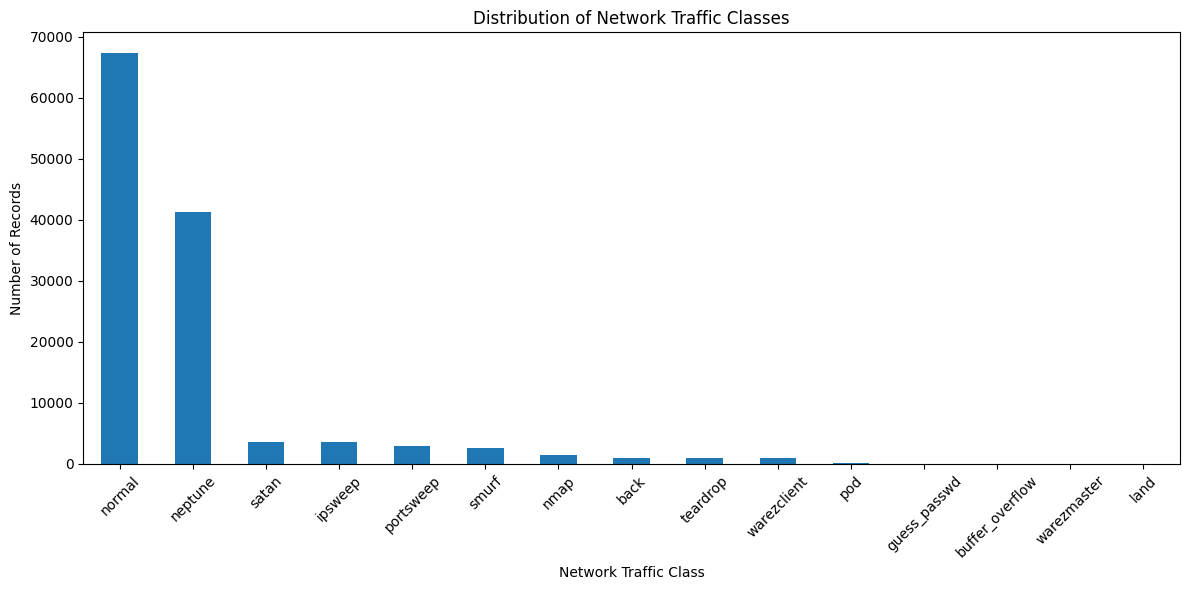

In [4]:

# Count different types of network traffic
class_counts = df['label'].value_counts()

print("Class Distribution:")
print(class_counts)

# Plot class distribution
plt.figure(figsize=(12, 6))
class_counts.head(15).plot(kind='bar')

plt.title("Distribution of Network Traffic Classes")
plt.xlabel("Network Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [5]:

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Separate input features and target label
X = df.drop(['label', 'difficulty'], axis=1)
y = df['label']

# Convert target labels into numerical values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("Labels converted successfully!")
print("Number of classes:", len(label_encoder.classes_))


Features shape: (125973, 41)
Target shape: (125973,)
Labels converted successfully!
Number of classes: 23


In [6]:

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training data: (100778, 41)
Testing data: (25195, 41)
Training labels: (100778,)
Testing labels: (25195,)


In [7]:

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(exclude=['object']).columns

# Convert categorical values into numerical values
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numerical', 'passthrough', numerical_cols)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)


Preprocessing completed!
Processed training data: (100778, 121)
Processed testing data: (25195, 121)


In [8]:
## Import required libraries

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import time


In [9]:

# Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)

start = time.time()
dt_model.fit(X_train_processed, y_train)
dt_predictions = dt_model.predict(X_test_processed)

dt_time = time.time() - start

print("Decision Tree Results")
print("Accuracy:", accuracy_score(y_test, dt_predictions))
print("Time taken:", round(dt_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test, dt_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))


Decision Tree Results
Accuracy: 0.9976582655288748
Time taken: 3.69 seconds

Classification Report:


ValueError: Number of classes, 22, does not match size of target_names, 23. Try specifying the labels parameter

In [10]:

from sklearn.metrics import classification_report

print("Decision Tree Classification Report:")

print(classification_report(
    y_test,
    dt_predictions,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


Decision Tree Classification Report:
                 precision    recall  f1-score   support

           back       0.99      1.00      1.00       191
buffer_overflow       0.86      1.00      0.92         6
      ftp_write       0.00      0.00      0.00         2
   guess_passwd       1.00      1.00      1.00        11
           imap       1.00      1.00      1.00         2
        ipsweep       1.00      0.99      1.00       720
           land       0.43      0.75      0.55         4
     loadmodule       0.00      0.00      0.00         2
       multihop       0.33      1.00      0.50         1
        neptune       1.00      1.00      1.00      8243
           nmap       0.99      1.00      0.99       299
         normal       1.00      1.00      1.00     13469
           perl       0.00      0.00      0.00         0
            phf       1.00      1.00      1.00         1
            pod       1.00      0.97      0.99        40
      portsweep       0.99      0.99      0.99    

In [11]:

# Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start = time.time()
rf_model.fit(X_train_processed, y_train)
rf_predictions = rf_model.predict(X_test_processed)

rf_time = time.time() - start

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Time taken:", round(rf_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test, rf_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))


Random Forest Results
Accuracy: 0.9984123834094066
Time taken: 13.48 seconds

Classification Report:


ValueError: Number of classes, 21, does not match size of target_names, 23. Try specifying the labels parameter

In [12]:

print("Random Forest Classification Report:")

print(classification_report(
    y_test,
    rf_predictions,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


Random Forest Classification Report:
                 precision    recall  f1-score   support

           back       0.99      1.00      1.00       191
buffer_overflow       1.00      0.67      0.80         6
      ftp_write       0.00      0.00      0.00         2
   guess_passwd       1.00      1.00      1.00        11
           imap       1.00      1.00      1.00         2
        ipsweep       1.00      1.00      1.00       720
           land       0.75      0.75      0.75         4
     loadmodule       0.00      0.00      0.00         2
       multihop       0.00      0.00      0.00         1
        neptune       1.00      1.00      1.00      8243
           nmap       0.99      0.99      0.99       299
         normal       1.00      1.00      1.00     13469
           perl       0.00      0.00      0.00         0
            phf       0.00      0.00      0.00         1
            pod       1.00      0.97      0.99        40
      portsweep       1.00      0.99      1.00    

In [13]:

# Scale data for SVM
scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

# Support Vector Machine
svm_model = LinearSVC(
    max_iter=5000,
    random_state=42
)

start = time.time()
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)

svm_time = time.time() - start

print("SVM Results")
print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Time taken:", round(svm_time, 2), "seconds")

print("\nClassification Report:")
print(classification_report(
    y_test, svm_predictions,
    target_names=label_encoder.classes_,
    zero_division=0
))


SVM Results
Accuracy: 0.9900377058940266
Time taken: 155.29 seconds

Classification Report:


ValueError: Number of classes, 21, does not match size of target_names, 23. Try specifying the labels parameter

In [14]:

print("SVM Classification Report:")

print(classification_report(
    y_test,
    svm_predictions,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


SVM Classification Report:
                 precision    recall  f1-score   support

           back       0.99      0.97      0.98       191
buffer_overflow       0.75      1.00      0.86         6
      ftp_write       0.00      0.00      0.00         2
   guess_passwd       1.00      1.00      1.00        11
           imap       1.00      1.00      1.00         2
        ipsweep       0.97      0.98      0.97       720
           land       0.67      1.00      0.80         4
     loadmodule       0.00      0.00      0.00         2
       multihop       0.00      0.00      0.00         1
        neptune       1.00      1.00      1.00      8243
           nmap       0.93      0.93      0.93       299
         normal       0.99      0.99      0.99     13469
           perl       0.00      0.00      0.00         0
            phf       1.00      1.00      1.00         1
            pod       0.98      1.00      0.99        40
      portsweep       0.99      0.99      0.99       586
   

       Algorithm  Accuracy  Time (seconds)
0  Decision Tree  0.997658        3.692352
1  Random Forest  0.998412       13.483721
2            SVM  0.990038      155.290956


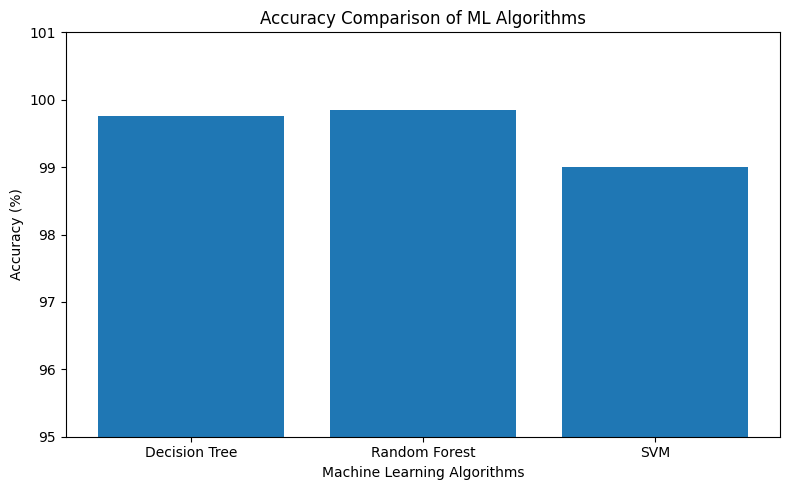

In [15]:

# Compare all three machine learning models

results = pd.DataFrame({
    'Algorithm': ['Decision Tree', 'Random Forest', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    'Time (seconds)': [dt_time, rf_time, svm_time]
})

print(results)

# Accuracy comparison graph
plt.figure(figsize=(8, 5))
plt.bar(results['Algorithm'], results['Accuracy'] * 100)

plt.title("Accuracy Comparison of ML Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(95, 101)

plt.tight_layout()
plt.show()


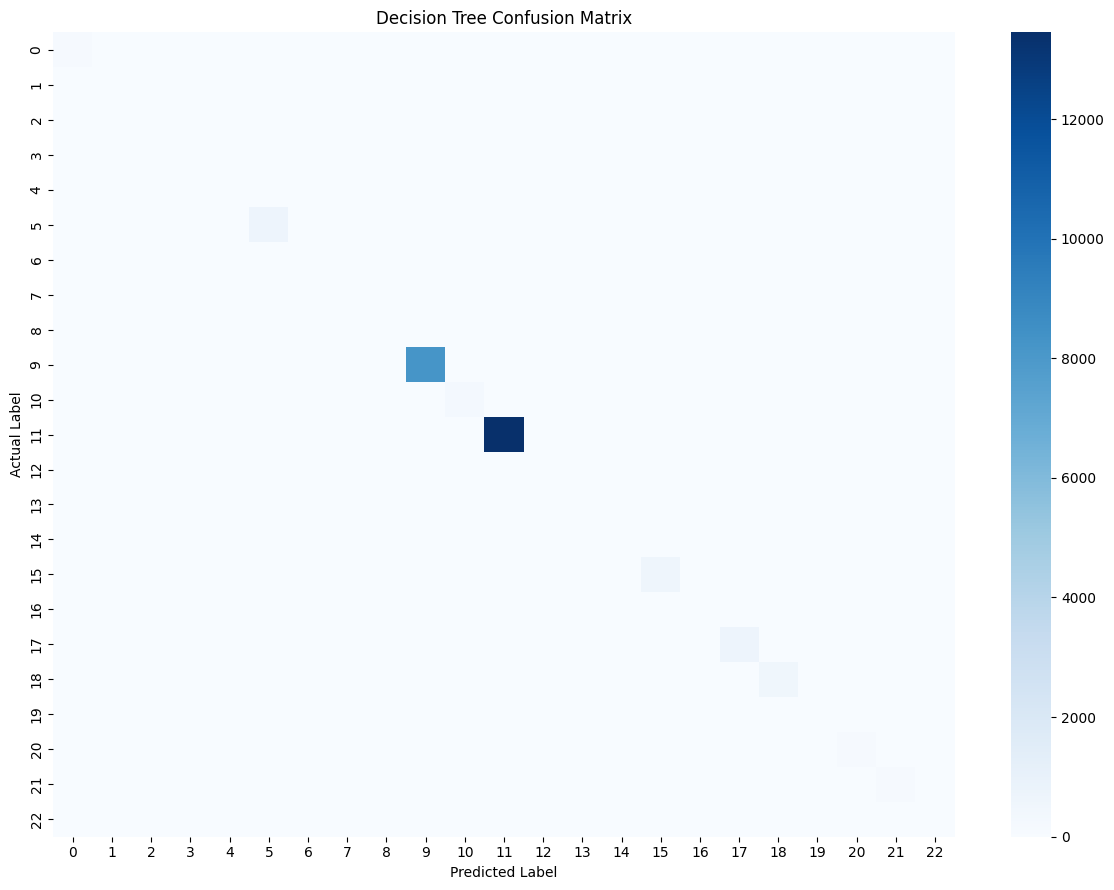

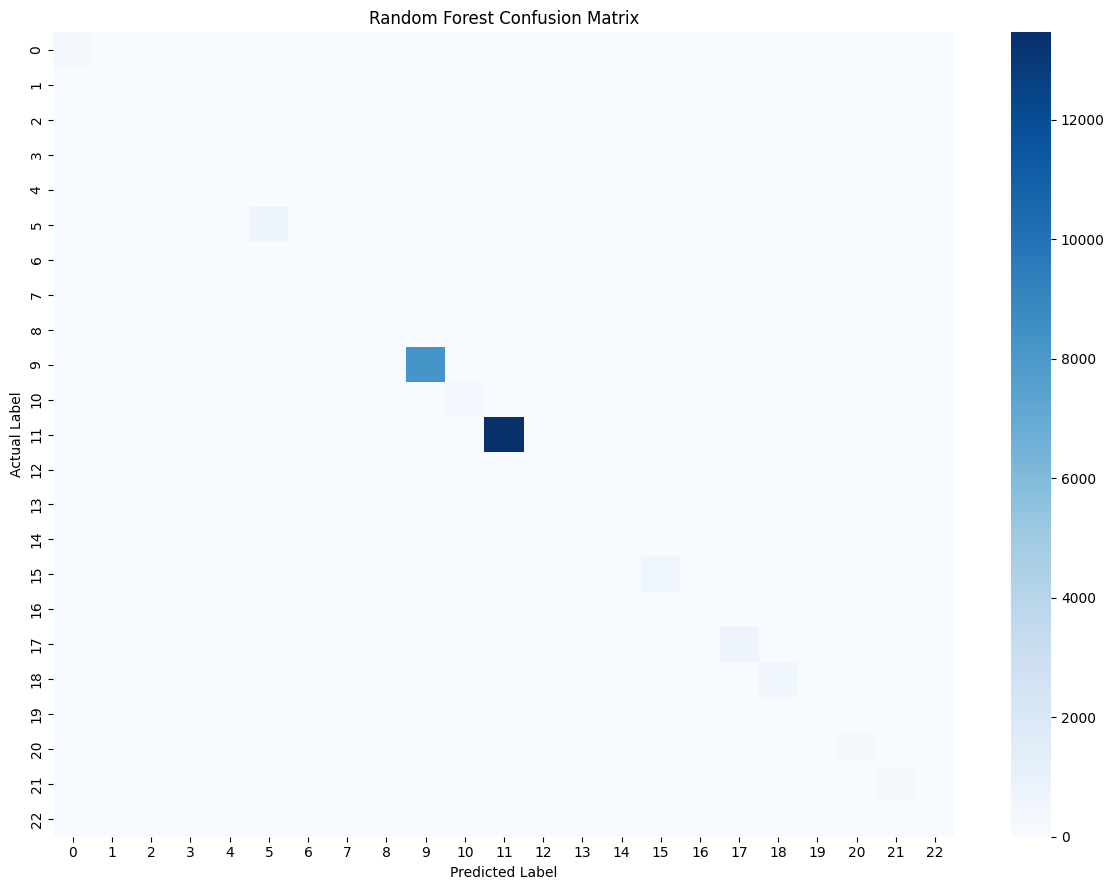

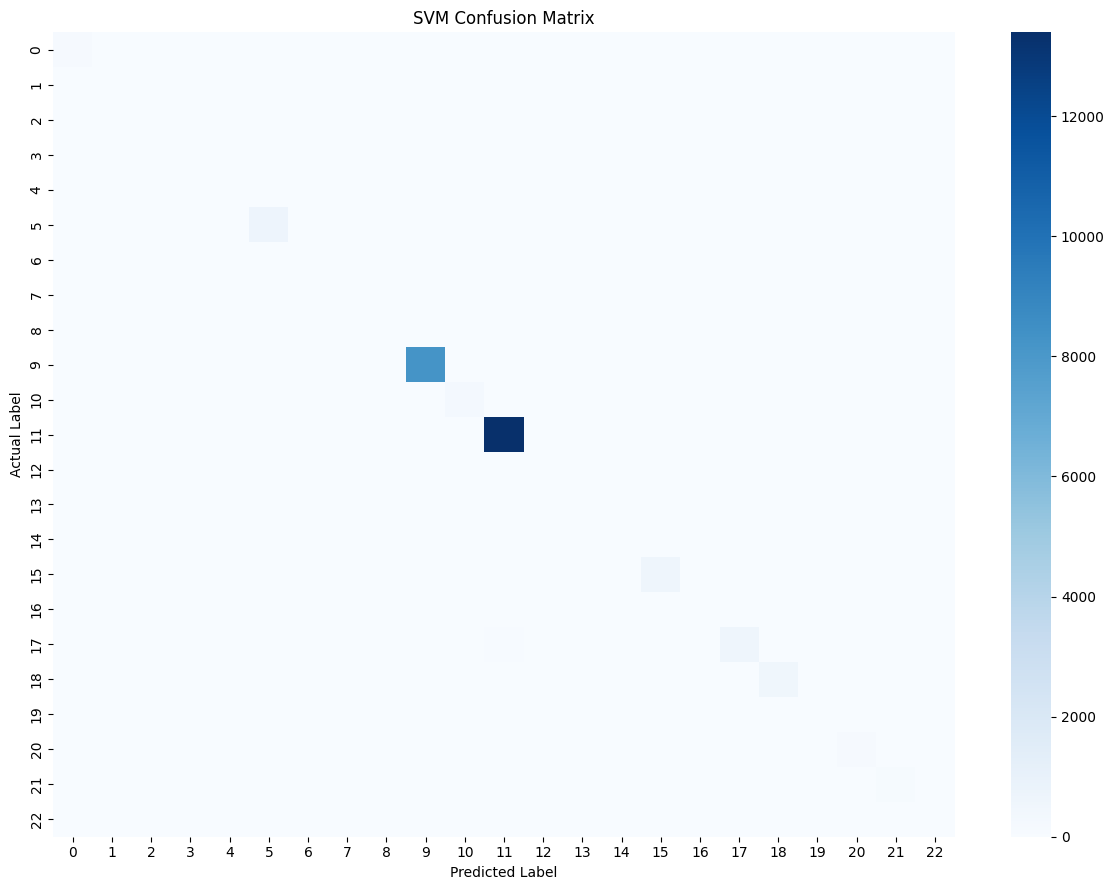

In [16]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Decision Tree Confusion Matrix
models = {
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "SVM": svm_predictions
}

for name, predictions in models.items():
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=range(len(label_encoder.classes_))
    )

    plt.figure(figsize=(12, 9))
    sns.heatmap(cm, cmap="Blues", annot=False, fmt="d")

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()


In [17]:

# Calculate precision, recall and F1-score
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    'Algorithm': ['Decision Tree', 'Random Forest', 'SVM'],
    'Accuracy': [
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, svm_predictions)
    ],
    'Precision': [
        precision_score(y_test, dt_predictions, average='weighted', zero_division=0),
        precision_score(y_test, rf_predictions, average='weighted', zero_division=0),
        precision_score(y_test, svm_predictions, average='weighted', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, dt_predictions, average='weighted', zero_division=0),
        recall_score(y_test, rf_predictions, average='weighted', zero_division=0),
        recall_score(y_test, svm_predictions, average='weighted', zero_division=0)
    ],
    'F1-Score': [
        f1_score(y_test, dt_predictions, average='weighted', zero_division=0),
        f1_score(y_test, rf_predictions, average='weighted', zero_division=0),
        f1_score(y_test, svm_predictions, average='weighted', zero_division=0)
    ]
})

print("Final Performance Comparison")
display(comparison)


Final Performance Comparison


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.997658,0.997771,0.997658,0.997697
1,Random Forest,0.998412,0.998136,0.998412,0.998263
2,SVM,0.990038,0.989735,0.990038,0.989766
